<a href="https://colab.research.google.com/github/tomzavi56/South-Africa-Labour-Market-Analysis/blob/main/notebooks/03_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully.
Shape: (74, 5)


,date,period,year,quarter_number,unemployment_rate
0,2008-01-01,2008Q1,2008,Q1,23.2
1,2008-04-01,2008Q2,2008,Q2,22.6
2,2008-07-01,2008Q3,2008,Q3,22.8
3,2008-10-01,2008Q4,2008,Q4,21.5
4,2009-01-01,2009Q1,2009,Q1,23.0


Descriptive statistics for unemployment rate:


,unemployment_rate
count,74.000000
mean,27.936486
std,3.843784
min,21.500000
25%,25.000000
50%,26.700000
75%,32.050000
max,35.300000


Lowest unemployment rate:


,3
date,2008-10-01
period,2008Q4
year,2008
quarter_number,Q4
unemployment_rate,21.5



Highest unemployment rate:


,55
date,2021-10-01
period,2021Q4
year,2021
quarter_number,Q4
unemployment_rate,35.3


,year,unemployment_rate
0,2008,22.525
1,2009,23.700
2,2010,24.875
3,2011,24.800
4,2012,24.875
5,2013,24.725
6,2014,25.100
7,2015,25.350
8,2016,26.725
9,2017,27.450


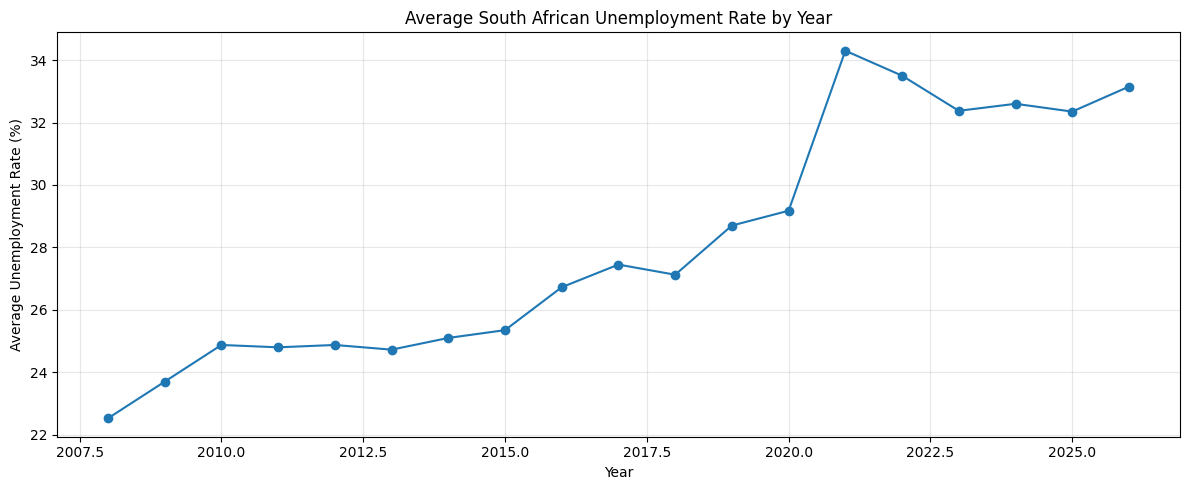

,year,quarters_observed
14,2022,4
15,2023,4
16,2024,4
17,2025,4
18,2026,2


,year,unemployment_rate
13,2021,34.300
14,2022,33.500
15,2023,32.375
16,2024,32.600
17,2025,32.350


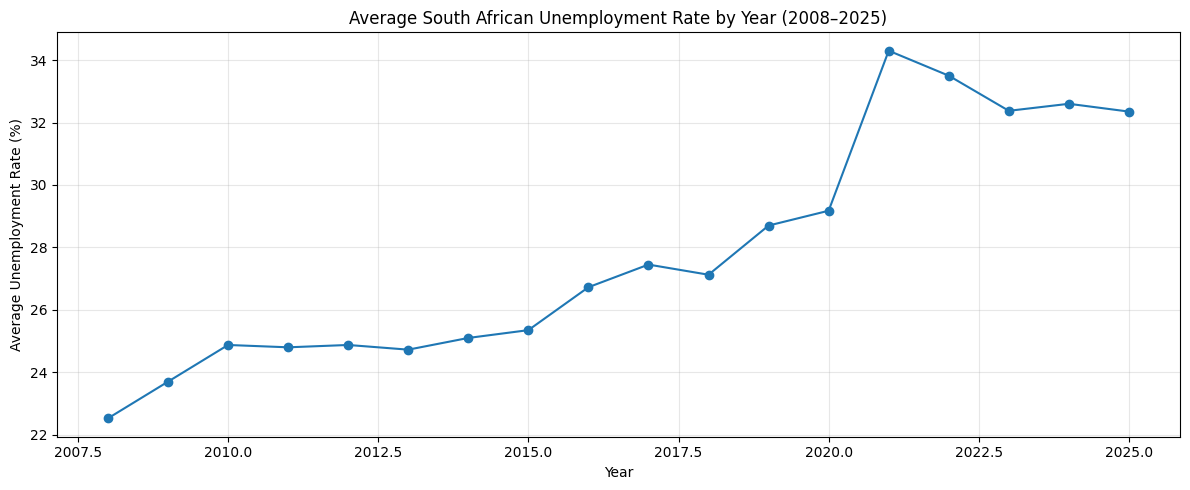

,period,unemployment_rate,quarterly_change
0,2008Q1,23.2,NaN
1,2008Q2,22.6,-0.6
2,2008Q3,22.8,0.2
3,2008Q4,21.5,-1.3
4,2009Q1,23.0,1.5
5,2009Q2,23.2,0.2
6,2009Q3,24.5,1.3
7,2009Q4,24.1,-0.4
8,2010Q1,25.1,1.0
9,2010Q2,25.1,0.0


Largest quarterly increase:


,50
date,2020-07-01
period,2020Q3
year,2020
quarter_number,Q3
unemployment_rate,30.8
quarterly_change,7.5



Largest quarterly decrease:


,49
date,2020-04-01
period,2020Q2
year,2020
quarter_number,Q2
unemployment_rate,23.3
quarterly_change,-6.8


,quarter_number,unemployment_rate
0,Q1,28.157895
1,Q2,28.005263
2,Q3,28.011111
3,Q4,27.555556


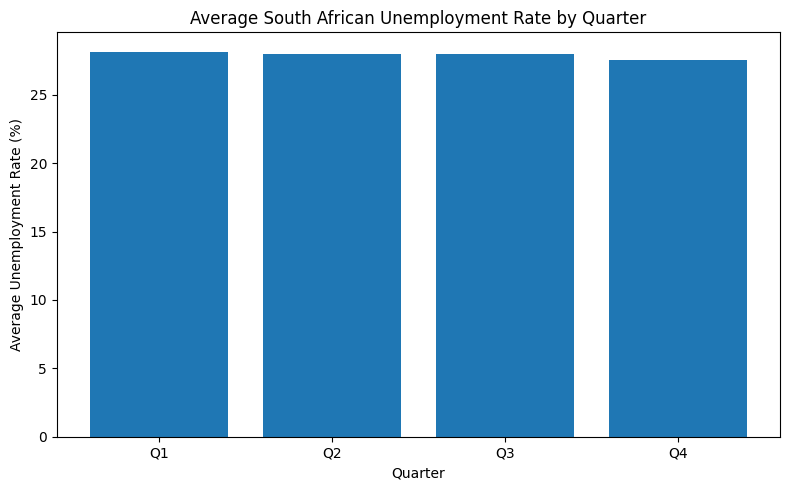

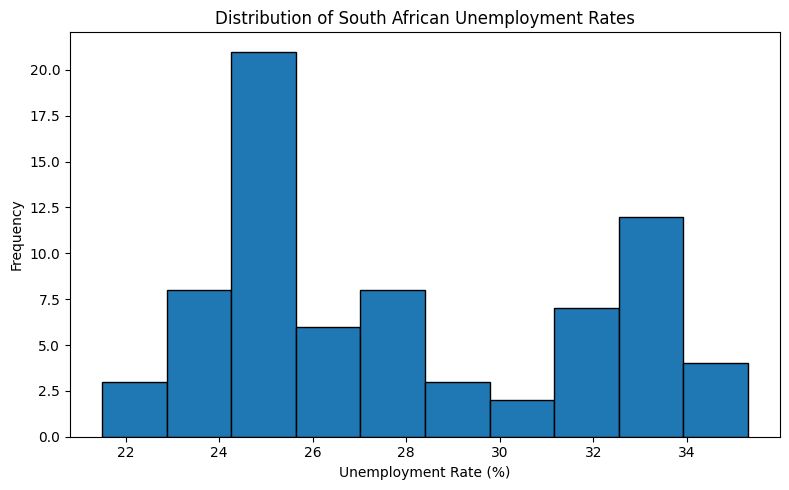

,period,unemployment_rate,moving_average_4q
0,2008Q1,23.2,NaN
1,2008Q2,22.6,NaN
2,2008Q3,22.8,NaN
3,2008Q4,21.5,22.525
4,2009Q1,23.0,22.475
5,2009Q2,23.2,22.625
6,2009Q3,24.5,23.050
7,2009Q4,24.1,23.700
8,2010Q1,25.1,24.225
9,2010Q2,25.1,24.700


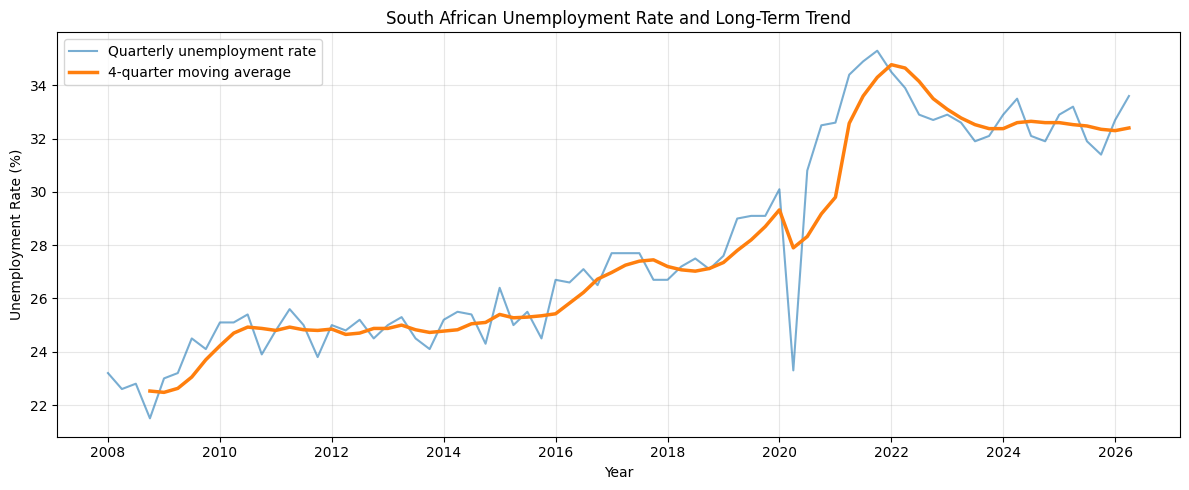

In [ ]:
# Importing the relevant packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading the cleaned unemployment dataset from GitHub

url = "https://raw.githubusercontent.com/tomzavi56/South-Africa-Labour-Market-Analysis/main/data/south_africa_unemployment_2008_2026.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

# Calculating descriptive statistics

print("Descriptive statistics for unemployment rate:")
display(df["unemployment_rate"].describe())

# Finding the lowest and highest unemployment rates

lowest_rate = df.loc[df["unemployment_rate"].idxmin()]
highest_rate = df.loc[df["unemployment_rate"].idxmax()]

print("Lowest unemployment rate:")
display(lowest_rate)

print("\nHighest unemployment rate:")
display(highest_rate)

# Calculating the average unemployment rate by year

yearly_average = (
    df.groupby("year")["unemployment_rate"]
    .mean()
    .reset_index()
)

display(yearly_average)

# Visualising the average unemployment rate by year

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_average["year"],
    yearly_average["unemployment_rate"],
    marker="o"
)

plt.title("Average South African Unemployment Rate by Year")
plt.xlabel("Year")
plt.ylabel("Average Unemployment Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Checking the number of observations available for each year

quarters_per_year = (
    df.groupby("year")
    .size()
    .reset_index(name="quarters_observed")
)

display(quarters_per_year.tail())

# Calculating annual averages for complete years

complete_years = quarters_per_year.loc[
    quarters_per_year["quarters_observed"] == 4,
    "year"
]

yearly_average_complete = (
    df[df["year"].isin(complete_years)]
    .groupby("year")["unemployment_rate"]
    .mean()
    .reset_index()
)

display(yearly_average_complete.tail())

# Visualising annual unemployment averages for complete years

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_average_complete["year"],
    yearly_average_complete["unemployment_rate"],
    marker="o"
)

plt.title(
    "Average South African Unemployment Rate by Year (2008–2025)"
)
plt.xlabel("Year")
plt.ylabel("Average Unemployment Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculating quarter-to-quarter changes in unemployment

df["quarterly_change"] = (
    df["unemployment_rate"].diff()
)

display(
    df[
        [
            "period",
            "unemployment_rate",
            "quarterly_change"
        ]
    ].head(10)
)

# Finding the largest quarterly increase in unemployment

largest_increase = df.loc[
    df["quarterly_change"].idxmax()
]

print("Largest quarterly increase:")
display(largest_increase)


# Finding the largest quarterly decrease in unemployment

largest_decrease = df.loc[
    df["quarterly_change"].idxmin()
]

print("\nLargest quarterly decrease:")
display(largest_decrease)

# Calculating the average unemployment rate by quarter

quarter_average = (
    df.groupby("quarter_number")["unemployment_rate"]
    .mean()
    .reindex(["Q1", "Q2", "Q3", "Q4"])
    .reset_index()
)

display(quarter_average)

# Visualising the average unemployment rate by quarter

plt.figure(figsize=(8, 5))

plt.bar(
    quarter_average["quarter_number"],
    quarter_average["unemployment_rate"]
)

plt.title("Average South African Unemployment Rate by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

# Visualising the distribution of unemployment rates

plt.figure(figsize=(8, 5))

plt.hist(
    df["unemployment_rate"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of South African Unemployment Rates")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Calculating a four-quarter moving average

df["moving_average_4q"] = (
    df["unemployment_rate"]
    .rolling(window=4)
    .mean()
)

display(
    df[
        [
            "period",
            "unemployment_rate",
            "moving_average_4q"
        ]
    ].head(10)
)

# Visualising unemployment and the four-quarter moving average

df["date"] = pd.to_datetime(df["date"])

plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["unemployment_rate"],
    label="Quarterly unemployment rate",
    alpha=0.6
)

plt.plot(
    df["date"],
    df["moving_average_4q"],
    label="4-quarter moving average",
    linewidth=2.5
)

plt.title("South African Unemployment Rate and Long-Term Trend")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()